# **Elite.Org**
## **Task 3 - Nasa Hazardous Objects Detection**
## AI Internship - Abdallah Fekry
---

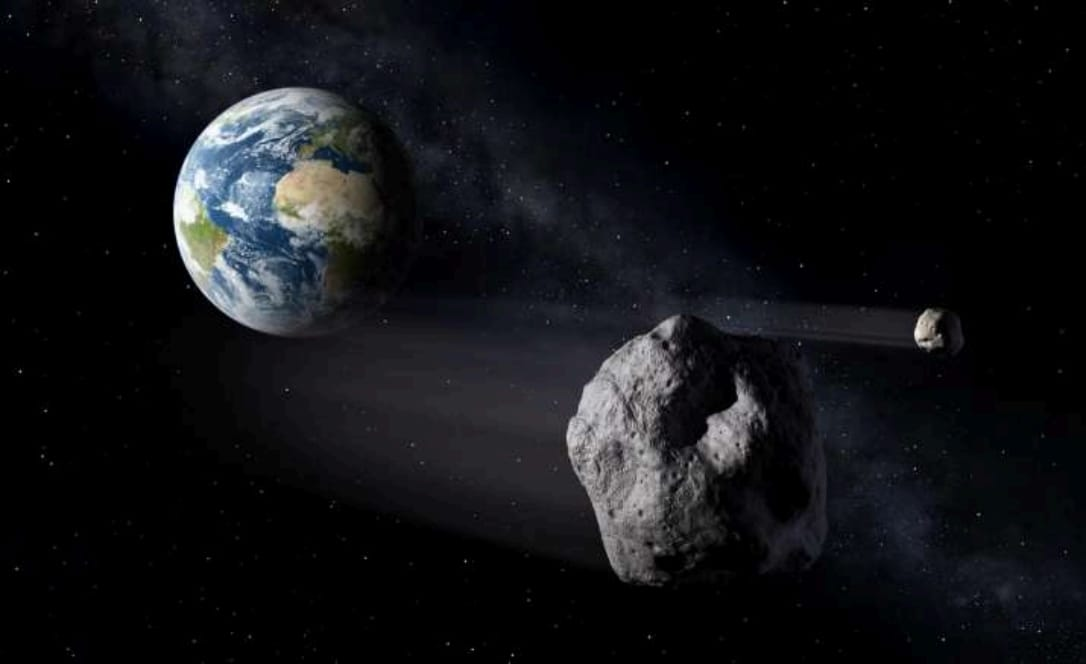

# Introduction
### The goal is to detect the hazardous objects, in these case the Recall is so important much more than the accuracy because we can to allow with misclassification the non hazardous objects (FP) but predicting that the hazardous objects as they aren't (FN) that may be very dangerous
---

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, precision_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [13]:
df = pd.read_csv("data/nasa-nearest-earth-objects(1910-2024)-dataset.csv")
df.head()

,neo_id,name,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,orbiting_body,relative_velocity,miss_distance,is_hazardous
0,2162117,162117 (1998 SD15),19.14,0.394962,0.883161,Earth,71745.401048,5.814362e+07,False
1,2349507,349507 (2008 QY),18.50,0.530341,1.185878,Earth,109949.757148,5.580105e+07,True
2,2455415,455415 (2003 GA),21.45,0.136319,0.304818,Earth,24865.506798,6.720689e+07,False
3,3132126,(2002 PB),20.63,0.198863,0.444672,Earth,78890.076805,3.039644e+07,False
4,3557844,(2011 DW),22.70,0.076658,0.171412,Earth,56036.519484,6.311863e+07,False


In [14]:
df.isnull().sum()

neo_id                     0
name                       0
absolute_magnitude        28
estimated_diameter_min    28
estimated_diameter_max    28
orbiting_body              0
relative_velocity          0
miss_distance              0
is_hazardous               0
dtype: int64

In [15]:
len(df)

338199

## Resolving Null values

In [16]:
df.dropna(inplace=True)
df.isnull().sum()

neo_id                    0
name                      0
absolute_magnitude        0
estimated_diameter_min    0
estimated_diameter_max    0
orbiting_body             0
relative_velocity         0
miss_distance             0
is_hazardous              0
dtype: int64

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 338171 entries, 0 to 338198
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   neo_id                  338171 non-null  int64  
 1   name                    338171 non-null  str    
 2   absolute_magnitude      338171 non-null  float64
 3   estimated_diameter_min  338171 non-null  float64
 4   estimated_diameter_max  338171 non-null  float64
 5   orbiting_body           338171 non-null  str    
 6   relative_velocity       338171 non-null  float64
 7   miss_distance           338171 non-null  float64
 8   is_hazardous            338171 non-null  bool   
dtypes: bool(1), float64(5), int64(1), str(2)
memory usage: 29.0 MB


In [18]:
print(len(df))
print(len(df.drop_duplicates()))

338171
338171


In [19]:
df.describe()

,neo_id,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,relative_velocity,miss_distance
count,3.381710e+05,338171.000000,338171.000000,338171.000000,338171.000000,3.381710e+05
mean,1.760041e+07,22.932525,0.157812,0.352878,51060.017994,4.153547e+07
std,2.287276e+07,2.911216,0.313885,0.701869,26399.922830,2.077411e+07
min,2.000433e+06,9.250000,0.000511,0.001143,203.346433,6.745533e+03
25%,3.373980e+06,20.740000,0.025384,0.056760,30710.626399,2.494495e+07
50%,3.742127e+06,22.800000,0.073207,0.163697,47557.046397,4.332724e+07
75%,5.405374e+07,25.100000,0.189041,0.422708,66673.223798,5.933961e+07
max,5.446281e+07,33.580000,37.545248,83.953727,291781.106613,7.479865e+07


## Detecting Outliers

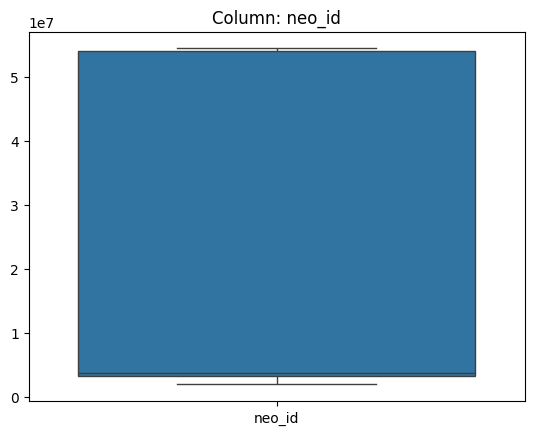

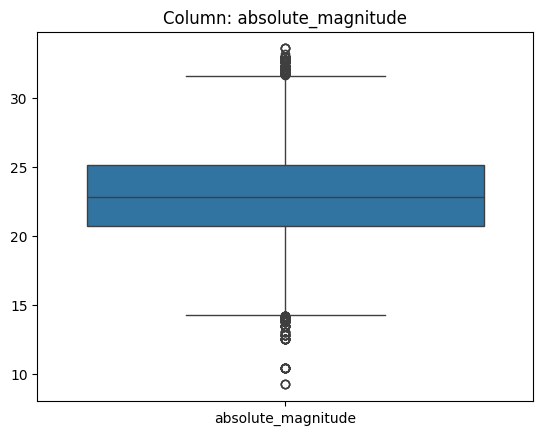

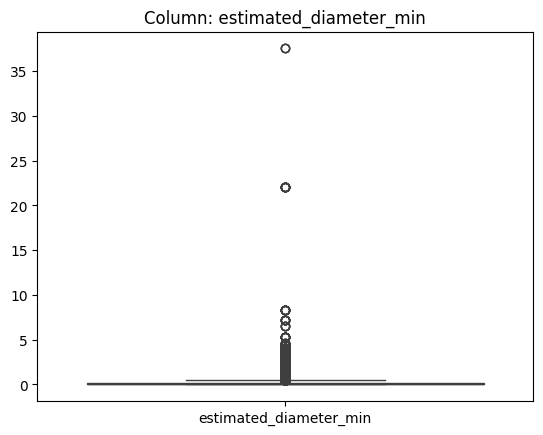

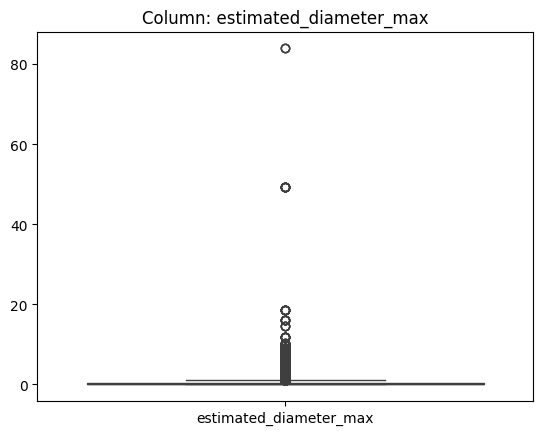

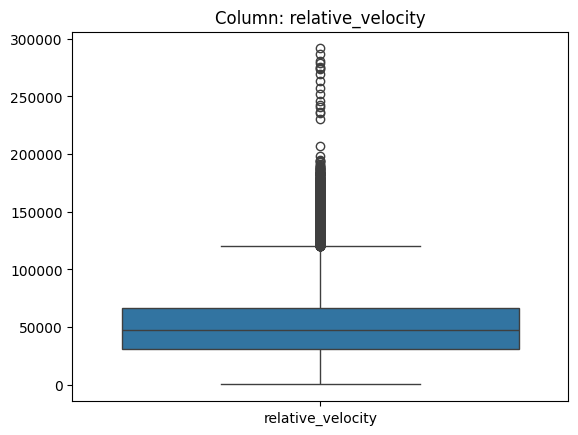

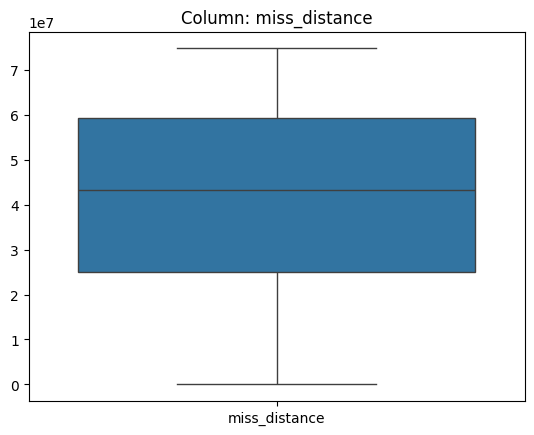

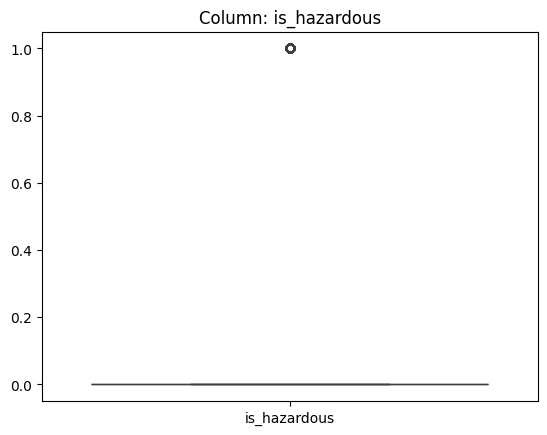

In [20]:
for c in df.columns:
    if df[c].dtype != 'str':
        sns.boxplot([df[c]])
        plt.title(f"Column: {c}")
        plt.show()

In [21]:
def resolve_outliers(df,c):
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[~((df[c] < lower_bound) | (df[c] > upper_bound))]
    sns.boxplot([df[c]])
    plt.title(f"Cleaned Column: {c}")
    plt.show()
    return df

In [22]:
df.columns

Index(['neo_id', 'name', 'absolute_magnitude', 'estimated_diameter_min',
       'estimated_diameter_max', 'orbiting_body', 'relative_velocity',
       'miss_distance', 'is_hazardous'],
      dtype='str')

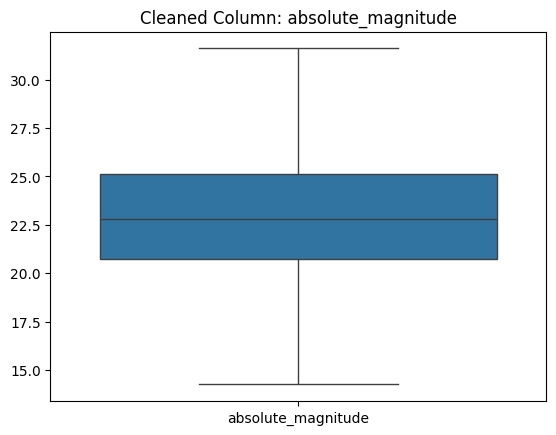

In [23]:
df = resolve_outliers(df, 'absolute_magnitude')

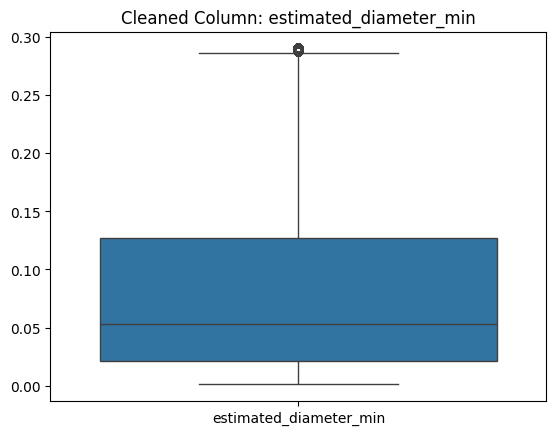

In [28]:
df = resolve_outliers(df, 'estimated_diameter_min')

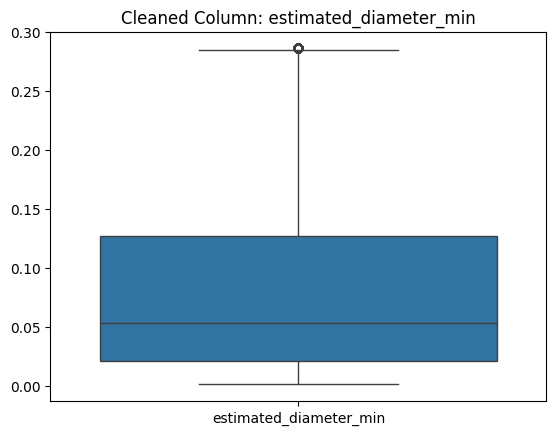

In [29]:
df = resolve_outliers(df, 'estimated_diameter_min') # resolve again

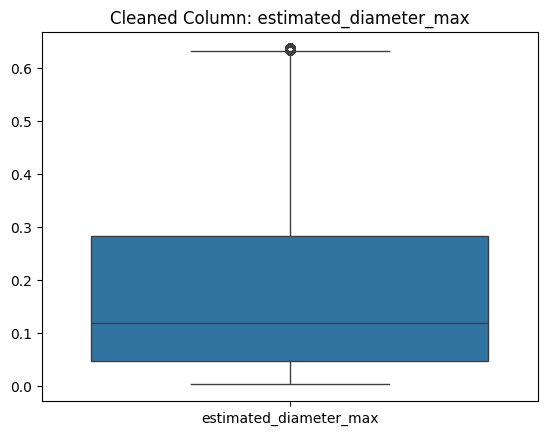

In [30]:
df = resolve_outliers(df, 'estimated_diameter_max')

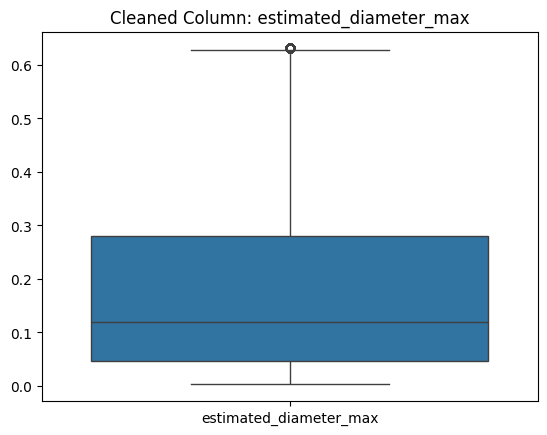

In [31]:
df = resolve_outliers(df, 'estimated_diameter_max')

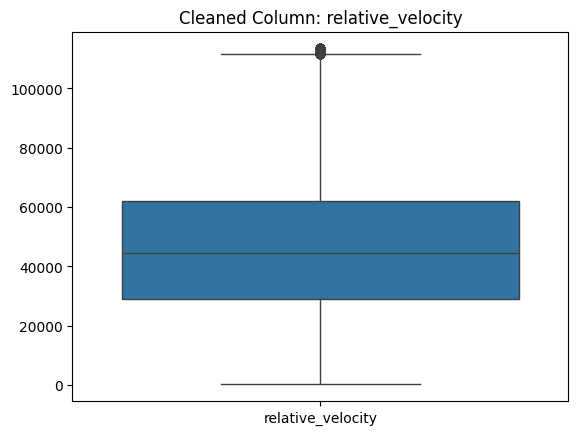

In [32]:
df = resolve_outliers(df, 'relative_velocity')

In [33]:
df.head(3)

,neo_id,name,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,orbiting_body,relative_velocity,miss_distance,is_hazardous
2,2455415,455415 (2003 GA),21.45,0.136319,0.304818,Earth,24865.506798,6.720689e+07,False
3,3132126,(2002 PB),20.63,0.198863,0.444672,Earth,78890.076805,3.039644e+07,False
4,3557844,(2011 DW),22.70,0.076658,0.171412,Earth,56036.519484,6.311863e+07,False


In [34]:
df.orbiting_body.unique()

<ArrowStringArray>
['Earth']
Length: 1, dtype: str

In [35]:
df.drop('neo_id', axis=1, inplace=True)
df.drop('name', axis=1, inplace=True)
df.drop('orbiting_body', axis=1, inplace=True)
df.head(3)

,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,relative_velocity,miss_distance,is_hazardous
2,21.45,0.136319,0.304818,24865.506798,6.720689e+07,False
3,20.63,0.198863,0.444672,78890.076805,3.039644e+07,False
4,22.70,0.076658,0.171412,56036.519484,6.311863e+07,False


In [36]:
df.is_hazardous = df.is_hazardous.astype(int)
df.head()

,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,relative_velocity,miss_distance,is_hazardous
2,21.45,0.136319,0.304818,24865.506798,6.720689e+07,0
3,20.63,0.198863,0.444672,78890.076805,3.039644e+07,0
4,22.70,0.076658,0.171412,56036.519484,6.311863e+07,0
5,25.00,0.026580,0.059435,47477.649832,4.290521e+07,0
6,21.50,0.133216,0.297879,57853.295346,2.727908e+07,1


<Axes: title={'center': 'Correlation Heatmap'}>

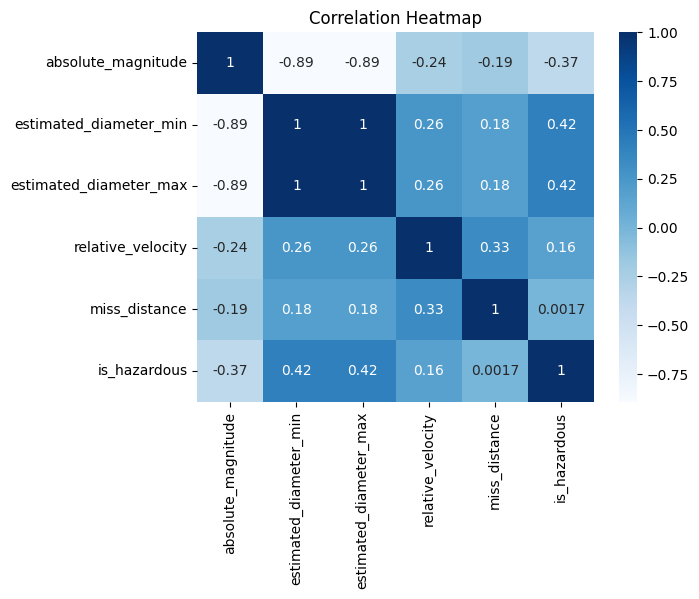

In [37]:
cr = df.corr()
plt.title("Correlation Heatmap")
sns.heatmap(cr, annot=True, cmap='Blues')

## Feature Engineering
1- features estimated_diameter_min and estimated_diameter_max are identical have correlation of value 1 and also -0.89 with feature absolute_magnitude, so i need to remove one of them to avoid overfitting

In [38]:
df.head()

,absolute_magnitude,estimated_diameter_min,estimated_diameter_max,relative_velocity,miss_distance,is_hazardous
2,21.45,0.136319,0.304818,24865.506798,6.720689e+07,0
3,20.63,0.198863,0.444672,78890.076805,3.039644e+07,0
4,22.70,0.076658,0.171412,56036.519484,6.311863e+07,0
5,25.00,0.026580,0.059435,47477.649832,4.290521e+07,0
6,21.50,0.133216,0.297879,57853.295346,2.727908e+07,1


In [39]:
df.columns

Index(['absolute_magnitude', 'estimated_diameter_min',
       'estimated_diameter_max', 'relative_velocity', 'miss_distance',
       'is_hazardous'],
      dtype='str')

In [40]:
df2 = df.copy()
df['estimated_diameter_min'] = (df['estimated_diameter_min']+df['estimated_diameter_max'])/2
df.drop("estimated_diameter_max", axis=1, inplace=True)
df.columns = ['absolute_magnitude', 'estimated_diameter_average', 'relative_velocity', 'miss_distance',
       'is_hazardous']
df.head()

,absolute_magnitude,estimated_diameter_average,relative_velocity,miss_distance,is_hazardous
2,21.45,0.220568,24865.506798,6.720689e+07,0
3,20.63,0.321768,78890.076805,3.039644e+07,0
4,22.70,0.124035,56036.519484,6.311863e+07,0
5,25.00,0.043007,47477.649832,4.290521e+07,0
6,21.50,0.215547,57853.295346,2.727908e+07,1


<Axes: title={'center': 'Correlation Heatmap'}>

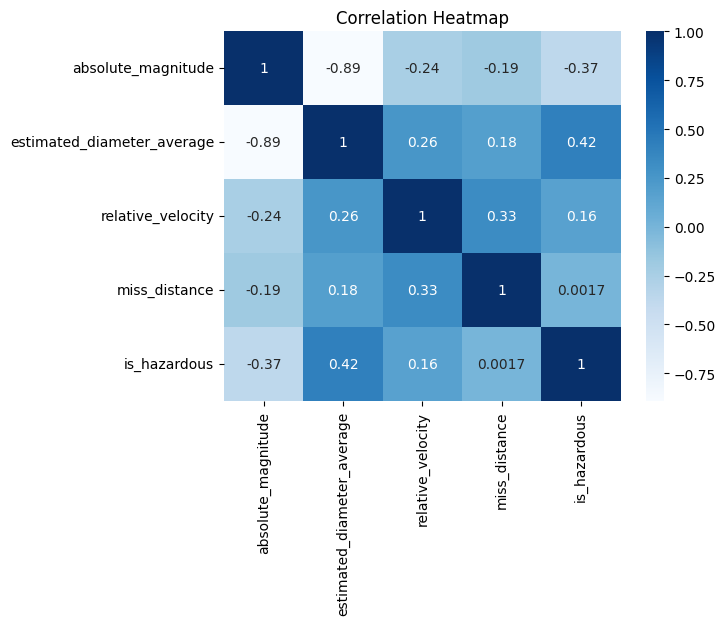

In [41]:
cr = df.corr()
plt.title("Correlation Heatmap")
sns.heatmap(cr, annot=True, cmap='Blues')

<Axes: title={'center': 'Correlation Heatmap'}>

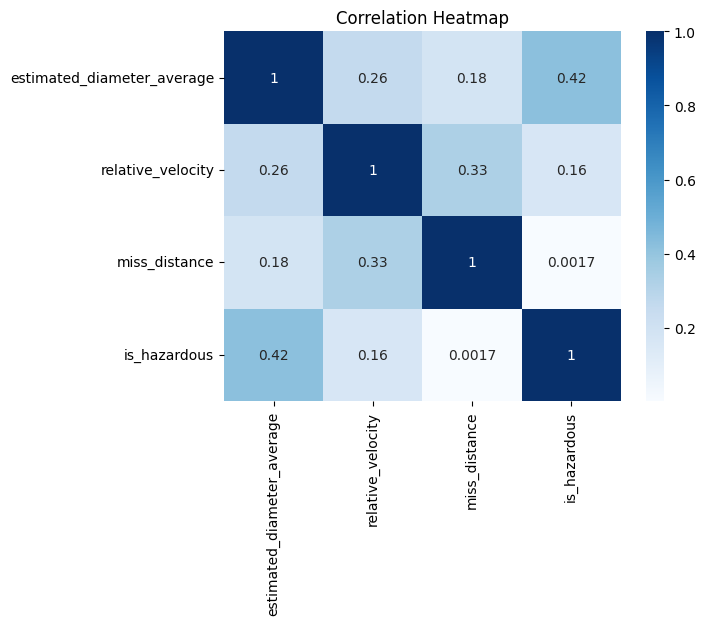

In [42]:
df.drop("absolute_magnitude", axis=1, inplace=True)
cr = df.corr()
plt.title("Correlation Heatmap")
sns.heatmap(cr, annot=True, cmap='Blues')

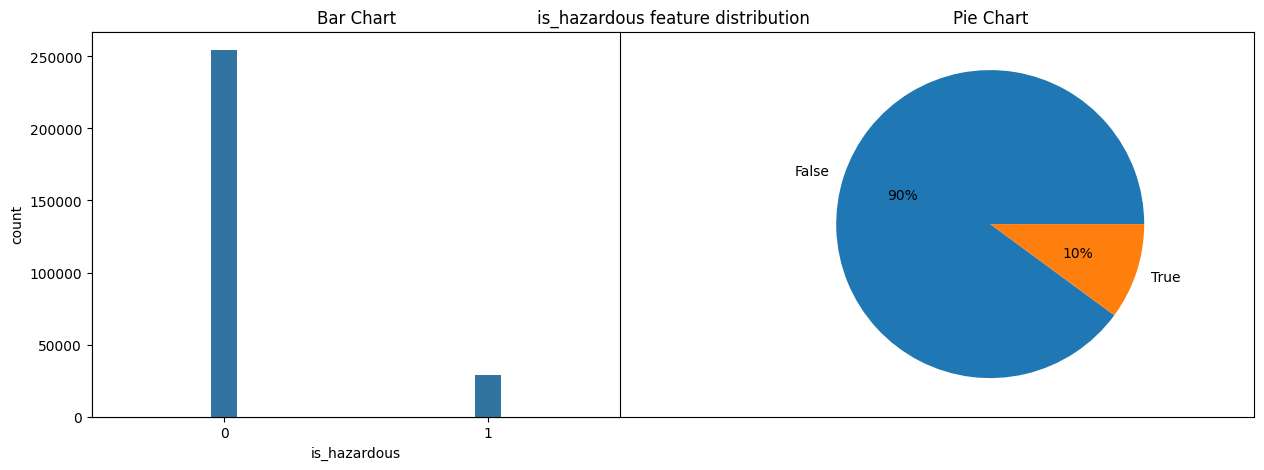

In [43]:
plt.figure(figsize=(15,5))
plt.title("is_hazardous feature distribution")
plt.xticks([])
plt.yticks([])
plt.subplot(1,2,1)
plt.title("Bar Chart")
sns.barplot(df.is_hazardous.value_counts(), width=0.1)
plt.subplot(1,2,2)
plt.title("Pie Chart")
plt.pie(df.is_hazardous.value_counts(), labels=["False","True"], autopct="%.0f%%")
plt.show()

In [44]:
df.head()

,estimated_diameter_average,relative_velocity,miss_distance,is_hazardous
2,0.220568,24865.506798,6.720689e+07,0
3,0.321768,78890.076805,3.039644e+07,0
4,0.124035,56036.519484,6.311863e+07,0
5,0.043007,47477.649832,4.290521e+07,0
6,0.215547,57853.295346,2.727908e+07,1


In [45]:
df.columns

Index(['estimated_diameter_average', 'relative_velocity', 'miss_distance',
       'is_hazardous'],
      dtype='str')

In [46]:
x = df.iloc[:,:-1].values
y = df.iloc[:,-1].values

In [47]:
scaler = StandardScaler()
x = scaler.fit_transform(x)

In [48]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=13)
print(x_train.shape, y_train.shape,
      x_test.shape, y_test.shape, sep='\n')

(226480, 3)
(226480,)
(56620, 3)
(56620,)


In [65]:
len(x)

283987

## Using Stratified K-fold Cross-validation

In [ ]:
model = LogisticRegression()
model.fit(x_train, y_train)

In [68]:
skf = StratifiedKFold(n_splits=1000)
score = cross_val_score(model, x, y, cv=skf)

In [69]:
score

array([0.89788732, 0.88380282, 0.87323944, 0.88028169, 0.87323944,
       0.86619718, 0.87323944, 0.87676056, 0.8943662 , 0.86971831,
       0.8943662 , 0.89788732, 0.87676056, 0.87323944, 0.90140845,
       0.8943662 , 0.89084507, 0.88380282, 0.86971831, 0.86267606,
       0.88028169, 0.87323944, 0.84507042, 0.88028169, 0.88380282,
       0.86619718, 0.86619718, 0.86267606, 0.90140845, 0.88028169,
       0.88732394, 0.88732394, 0.87676056, 0.86267606, 0.88380282,
       0.87676056, 0.8943662 , 0.87323944, 0.88380282, 0.88732394,
       0.85915493, 0.88732394, 0.88028169, 0.87676056, 0.90492958,
       0.85915493, 0.86619718, 0.86619718, 0.90140845, 0.8415493 ,
       0.86971831, 0.88732394, 0.88380282, 0.87676056, 0.88732394,
       0.8943662 , 0.86267606, 0.86267606, 0.89084507, 0.88380282,
       0.87676056, 0.8943662 , 0.88028169, 0.86619718, 0.89084507,
       0.89084507, 0.88028169, 0.87676056, 0.88380282, 0.86619718,
       0.88380282, 0.9084507 , 0.88380282, 0.90140845, 0.89084

In [70]:
np.mean(score)

0.8868826830239387

In [74]:
yp_train = model.predict(x_train)
yp = model.predict(x_test)

In [75]:
train_accuracy = accuracy_score(y_train, yp_train)
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Training Accuracy:", round(train_accuracy*100,2))
print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Training Accuracy: 88.69
Testing Accuracy: 88.62
Testing Recall: 12.41


<Axes: >

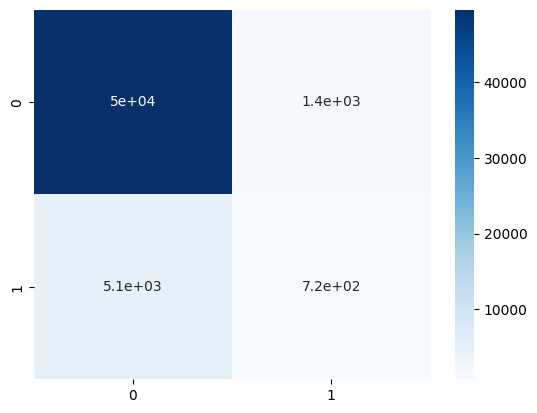

In [76]:
cm = confusion_matrix(y_test, yp)
sns.heatmap(cm, annot=True, cmap='Blues')

### Refused

---

## Using Support Vector Machine

In [77]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(x_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [78]:
yp = svc.predict(x_test)
yp_train =svc.predict(x_train)

In [79]:
train_accuracy = accuracy_score(y_train, yp_train)
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Training Accuracy:", round(train_accuracy*100,2))
print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Training Accuracy: 90.85
Testing Accuracy: 90.85
Testing Recall: 14.2


<Axes: >

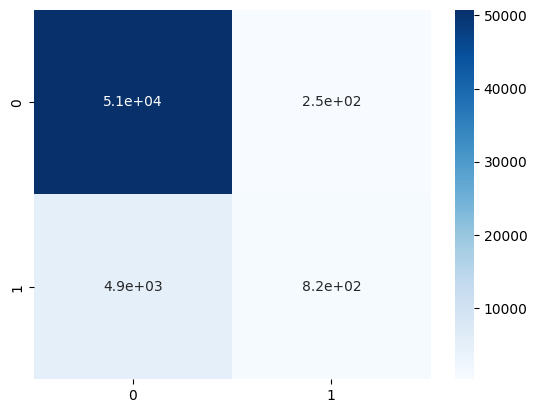

In [80]:
cm = confusion_matrix(y_test, yp)
sns.heatmap(cm, annot=True, cmap='Blues')

### Refused

---

## Visualize data in 2D view

In [81]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit_transform(x)
x_2d = pca.transform(x)
x_2d.shape


(283987, 2)

In [82]:
y[0]

0

In [83]:
c1x = []
c1y = []
c2x = []
c2y = []
for i in range(len(x_2d)):
    if y[i] == 0:
        c1x.append(x_2d[i][0])
        c1y.append(x_2d[i][1])
    else:
        c2x.append(x_2d[i][0])
        c2y.append(x_2d[i][1])

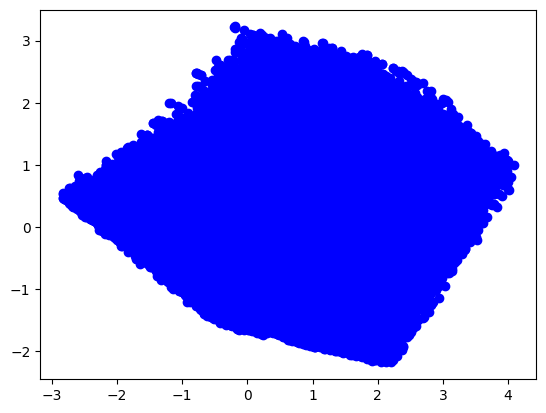

In [84]:
plt.scatter(c1x,c1y, color='blue')

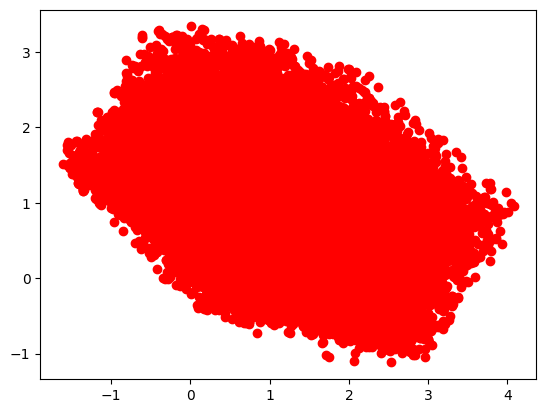

In [85]:
plt.scatter(c2x,c2y, color='red')

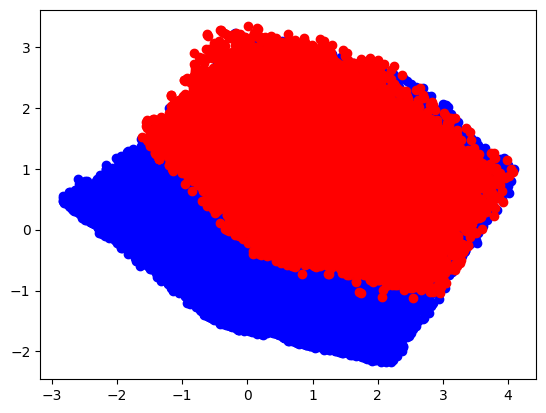

In [86]:
plt.scatter(c1x,c1y, color='blue')
plt.scatter(c2x,c2y, color='red')

## The data is overlapped so it can't be lineary separatable, So decision trees and RF will be more suitable here

---

## Using Decision Tree

In [87]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier()
tree.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [88]:
score.mean()

0.8868826830239387

In [89]:
yp = tree.predict(x_test)

In [90]:
# train_accuracy = accuracy_score(y_train, yp_train)
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

# print("Training Accuracy:", round(train_accuracy*100,2))
print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Testing Accuracy: 91.31
Testing Recall: 58.36


## Refused: but i think i made progress
___

## Random Forest

In [91]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [92]:
yp = rf.predict(x_test)

In [93]:
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Testing Accuracy: 92.84
Testing Recall: 48.61


## Okay, now we are going back, not forward 😂

---

## Using Oversamplig technique with Decision Tree

In [94]:
smote = SMOTE(random_state=13)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)

In [95]:
print("Before SMOTE:")
print(pd.Series(y_train).value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Before SMOTE:
0    204167
1     23022
Name: count, dtype: int64

After SMOTE:
0    204167
1    204167
Name: count, dtype: int64


In [96]:
tree = DecisionTreeClassifier()
tree.fit(x_train_resampled, y_train_resampled)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [97]:
yp = tree.predict(x_test)

In [98]:
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Testing Accuracy: 91.57
Testing Recall: 65.26


### Still Refused, i need a little bit more Recall

---

## Using Oversampling with Random Forest

In [99]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(x_train_resampled, y_train_resampled)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [100]:
yp = rf.predict(x_test)

In [101]:
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Testing Accuracy: 89.07
Testing Recall: 81.03


### Thats nice, but can get better
---

## Using Downsampling and Oversamplig with Random Forest

In [49]:
df.is_hazardous.value_counts()

is_hazardous
0    254531
1     28569
Name: count, dtype: int64

In [85]:
df2 = df[df['is_hazardous'] == 0].sample(n=30000)
df2 = pd.concat([df2, df[df['is_hazardous'] == 1]], ignore_index=True)

In [86]:
df2.head()

,estimated_diameter_average,relative_velocity,miss_distance,is_hazardous
0,0.039223,37132.994331,3.764357e+07,0
1,0.006216,13194.195414,6.657523e+06,0
2,0.297538,64405.728498,2.352169e+07,0
3,0.215547,61052.949752,6.267198e+07,0
4,0.142411,23215.468199,2.775538e+07,0


In [87]:
df2.tail()

,estimated_diameter_average,relative_velocity,miss_distance,is_hazardous
58564,0.225706,76913.014352,1.188187e+07,1
58565,0.227794,89118.566309,3.766458e+07,1
58566,0.438069,82457.667589,6.752365e+07,1
58567,0.352811,54747.600249,1.067043e+07,1
58568,0.352811,54747.577829,1.067038e+07,1


In [88]:
df2['is_hazardous'].value_counts()

is_hazardous
0    30000
1    28569
Name: count, dtype: int64

In [89]:
x = df2.iloc[:,:-1].values
y = df2.iloc[:,-1].values

In [90]:
x = scaler.transform(x)

In [91]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=13)
print(x_train.shape, y_train.shape,
      x_test.shape, y_test.shape, sep='\n')

(46855, 3)
(46855,)
(11714, 3)
(11714,)


In [73]:
smote = SMOTE(random_state=13)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)

In [92]:
pd.Series(y_train).value_counts()

0    24023
1    22832
Name: count, dtype: int64

In [93]:
pd.Series(y_test).value_counts()

0    5977
1    5737
Name: count, dtype: int64

In [95]:
from sklearn.ensemble import RandomForestClassifier

In [96]:
rf = RandomForestClassifier()
rf.fit(x_train_resampled, y_train_resampled)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [97]:
yp = rf.predict(x_test)

In [98]:
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)

print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Testing Accuracy: 92.85
Testing Recall: 99.02


<Axes: >

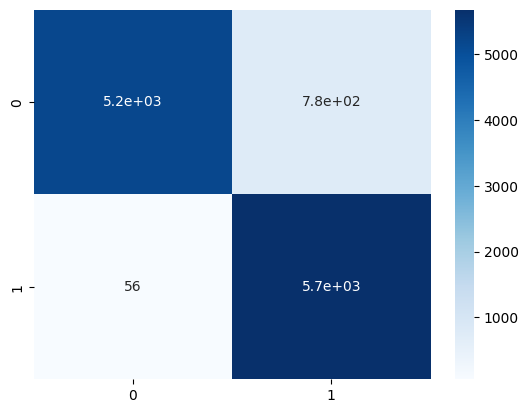

In [99]:
cm = confusion_matrix(y_test, yp)
sns.heatmap(cm, annot=True, cmap='Blues')

In [100]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(x_train_resampled, y_train_resampled)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candida

In [101]:
print(grid_search.best_score_)

0.988423379016937


In [102]:
best_rf = grid_search.best_estimator_
yp = best_rf.predict(x_test)

In [105]:
yp_train = best_rf.predict(x_train)

In [106]:
accuracy = accuracy_score(y_test, yp)
recall = recall_score(y_test, yp)
train_accuracy = accuracy_score(y_train, yp_train)
train_recall = recall_score(y_train, yp_train)

print("Training Accuracy:", round(train_accuracy*100,2))
print("Training Recall:", round(train_recall*100,2))
print("Testing Accuracy:", round(accuracy*100,2))
print("Testing Recall:", round(recall*100,2))

Training Accuracy: 89.96
Training Recall: 99.66
Testing Accuracy: 90.05
Testing Recall: 99.67


In [104]:
print("\nClassification Report:")
print(classification_report(y_test, yp))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.81      0.89      5977
           1       0.83      1.00      0.91      5737

    accuracy                           0.90     11714
   macro avg       0.91      0.90      0.90     11714
weighted avg       0.92      0.90      0.90     11714



<Axes: >

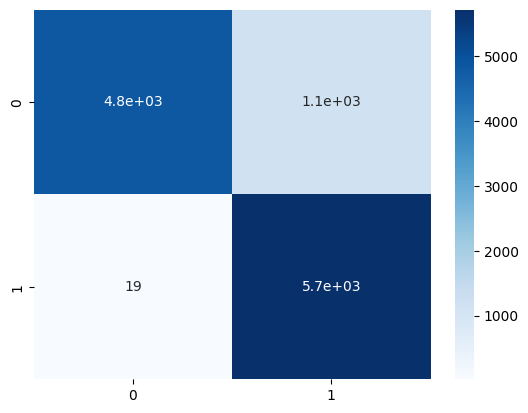

In [107]:
cm = confusion_matrix(y_test, yp)
sns.heatmap(cm, annot=True, cmap='Blues')

### Accepted

In [108]:
# storing the model
import pickle
with open('model.pkl', 'wb') as f:
    pickle.dump(best_rf, f)

In [109]:
import joblib
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

---
## **Conclusion**
### **The best solution:** by removing the outliers, missing data, correlated features in the cleaning phase, and by using the oversampling and downsampling teqniques together with a non linear model (Random Forest) with Standard scaler for the features it gives the best model performance with Testing Recall 98.66% and total Test Accuracy 92%.
### This model is generalized and capable of identify the hazardous objects by 98.66% wich is that main task and these means that it is doing its job perfectly.

---